# AE611 AERODYNAMICS
## Assignment: Vortex Panel Method in 2D

**Name:** SOUMEN SARDAR &nbsp;&nbsp; **Roll No.:** SC26M017



## Contents
1. Algorithms for the constant-strength and linear-strength vortex panel methods
2. Python implementation: `vortex_panel_method_0()` and `vortex_panel_method_1()`
3. Verification on a circular cylinder (convergence)
4. Verification on NACA 0024 and NACA 4415 (number of panels, panel-length distribution)
5. Prediction of airfoil characteristics ($C_l$–$\alpha$, $C_p$ distributions)
6. Limitations of the prediction as thickness increases
7. Conclusions
8. References and acknowledgements

*Conventions:* chord $c=1$, $V_\infty=1$, boundary points are ordered **clockwise** (for the airfoils: lower surface from trailing edge to leading edge, then upper surface to the trailing edge), so the panel normal $\mathbf n=(-\sin\theta,\cos\theta)$ points out of the body.

**Test bodies:** circular cylinder (exact solution known), **NACA 0024** (symmetric) and **NACA 4415** (non-symmetric).

## 1. Algorithms

### 1.1 Common set-up

The body is replaced by $N$ straight panels joining the boundary points $(X_k,Y_k)$, $k=1,\dots,N+1$ ($(X_{N+1},Y_{N+1})=(X_1,Y_1)$). A vortex sheet of strength $\gamma$ is placed on the panels. For panel $j$:

$$S_j=\sqrt{\Delta X_j^2+\Delta Y_j^2},\qquad \theta_j=\operatorname{atan2}(\Delta Y_j,\Delta X_j),\qquad \text{control point } (x_i,y_i)=\text{midpoint of panel } i .$$

The control point $i$ is written in the local frame of panel $j$ (origin at its start point, $\xi$ along the panel):

$$\xi=(x_i-X_j)\cos\theta_j+(y_i-Y_j)\sin\theta_j,\qquad \eta=-(x_i-X_j)\sin\theta_j+(y_i-Y_j)\cos\theta_j,$$

$$\phi_1=\operatorname{atan2}(\eta,\xi),\quad \phi_2=\operatorname{atan2}(\eta,\xi-S_j),\quad r_1=\sqrt{\xi^2+\eta^2},\quad r_2=\sqrt{(\xi-S_j)^2+\eta^2}.$$

Two conditions fix the unknown strengths:

* **Flow tangency** at every control point: $(\mathbf V_\infty+\mathbf v_{\rm induced})\cdot\mathbf n_i=0$, where $\mathbf V_\infty=V_\infty(\cos\alpha,\sin\alpha)$, so $\mathbf V_\infty\cdot\mathbf n_i=V_\infty\sin(\alpha-\theta_i)$.
* **Kutta condition** at the trailing edge: the strengths of the first and last panels cancel, $\gamma_{\rm first}+\gamma_{\rm last}=0$ (the flow leaves the trailing edge smoothly with finite speed).

Because the flow inside the body is zero, the velocity just outside the surface equals the local sheet strength, $V_t=\gamma$, giving $C_p=1-(V_t/V_\infty)^2$. The circulation is $\Gamma=\sum \gamma S$ and, by Kutta–Joukowski, $C_l=2\Gamma/(V_\infty c)$.

### 1.2 Algorithm A – constant-strength vortex panels (`vortex_panel_method_0`)

**Input:** $X_k,Y_k$, $\alpha$, $V_\infty$ &nbsp;&nbsp; **Unknowns:** $\gamma_1,\dots,\gamma_N$ (one constant value per panel)

1. Compute $S_j,\ \theta_j$ and the control points for all panels.
2. For every pair $(i,j)$ with $i\neq j$ compute $\xi,\eta,\phi_1,\phi_2,r_1,r_2$ of control point $i$ in the frame of panel $j$.
3. Normal velocity at $i$ per unit $\gamma_j$ (along-panel part $\Delta\phi/2\pi$ and across-panel part $\ln(r_2/r_1)/2\pi$ projected on $\mathbf n_i$):
$$A_{ij}=\frac{1}{2\pi}\Big[(\phi_2-\phi_1)\sin(\theta_j-\theta_i)+\ln\frac{r_2}{r_1}\cos(\theta_i-\theta_j)\Big],\qquad A_{ii}=0 .$$
4. Right-hand side from the free stream: $b_i=V_\infty\sin(\theta_i-\alpha)$, so that $\sum_j A_{ij}\gamma_j=b_i$.
5. Kutta condition: replace the last equation by $\gamma_1+\gamma_N=0$ (row $N$ of $A$ = $[1,0,\dots,0,1]$, $b_N=0$).
6. Solve the $N\times N$ system $A\boldsymbol\gamma=\mathbf b$.
7. Post-process: $C_{p,i}=1-(\gamma_i/V_\infty)^2$, $\ \Gamma=\sum_i\gamma_iS_i$, $\ C_l=2\Gamma/(V_\infty c)$.

### 1.3 Algorithm B – linear-strength vortex panels (`vortex_panel_method_1`)

**Unknowns:** $\gamma_1,\dots,\gamma_{N+1}$, one value per boundary point; $\gamma$ varies linearly on panel $j$ from $\gamma_j$ to $\gamma_{j+1}$ and is continuous at the corners.

1. Steps 1–2 of Algorithm A. For a panel acting on its **own** control point use $\xi=S_i/2,\ \eta=0,\ \phi_2-\phi_1=\pi,\ \ln(r_2/r_1)=0$.
2. Evaluate the integrals of the constant and the linearly varying part of $\gamma$ ($L=\ln(r_2/r_1)$, $\Delta\phi=\phi_2-\phi_1$):
$$J_1=\Delta\phi,\quad J_2=-L,\quad K_1=\xi\,\Delta\phi+\eta L,\quad K_2=-\xi L-S_j+\eta\,\Delta\phi .$$
3. Velocity components in the frame of panel $j$ per unit $\gamma_j$ ("a") and per unit $\gamma_{j+1}$ ("b"):
$$u_\xi^{a}=\frac{J_1-K_1/S_j}{2\pi},\ \ u_\xi^{b}=\frac{K_1/S_j}{2\pi},\qquad u_\eta^{a}=-\frac{J_2-K_2/S_j}{2\pi},\ \ u_\eta^{b}=-\frac{K_2/S_j}{2\pi}.$$
4. Normal component at control point $i$: $\ C^{a,b}_{ij}=u_\xi^{a,b}\sin(\theta_j-\theta_i)+u_\eta^{a,b}\cos(\theta_i-\theta_j)$. Add $C^a_{ij}$ to $A_{i,j}$ and $C^b_{ij}$ to $A_{i,j+1}$ (interior nodes receive contributions from two panels).
5. Right-hand side $b_i=V_\infty\sin(\theta_i-\alpha)$ for $i=1..N$.
6. Kutta condition as the extra $(N+1)$-th equation: $\gamma_1+\gamma_{N+1}=0$. No equation has to be dropped: $A$ is $(N+1)\times(N+1)$.
7. Solve for $\gamma_1,\dots,\gamma_{N+1}$.
8. Post-process: speed at control point $V_{t,i}=\tfrac12(\gamma_i+\gamma_{i+1})$, $\ C_{p,i}=1-(V_{t,i}/V_\infty)^2$, $\ \Gamma=\sum_iS_iV_{t,i}$, $\ C_l=2\Gamma/(V_\infty c)$.

## 2. Implementation

All functions take the boundary points `xb, yb`, the angle of attack `alpha_deg` and `V_inf`, and **return a dictionary** with the vortex strengths `gamma`, pressure coefficients `Cp` (one per panel), lift coefficient `Cl`, circulation `Gamma`, and the control points `xc, yc` and panel lengths `S`.

The influence coefficients are computed for all panel pairs at once with NumPy arrays (no Python double loop), so N = 1000 runs in well under a second. The arithmetic is the same as in the step-by-step algorithms above.

### 2.1 Geometry

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.35,
                     "axes.titlesize": 11, "legend.fontsize": 8})

In [ ]:
def cylinder_panels(n, r=1.0):
    """n panels on a circle of radius r. Boundary points run clockwise from (r, 0)."""
    theta = np.linspace(2*np.pi, 0.0, n + 1)
    return r*np.cos(theta), r*np.sin(theta)


def naca4_panels(code, n, spacing="cosine"):
    """Boundary points of a NACA 4-digit airfoil (closed trailing edge, chord = 1).

    n       : number of panels (even, n/2 per surface)
    spacing : 'cosine'  - clusters points at LE and TE
              'uniform' - equal steps in x
              'le'      - clusters at the leading edge only
              'te'      - clusters at the trailing edge only
    Points run clockwise: lower surface TE -> LE, then upper surface LE -> TE.
    """
    if n % 2:
        raise ValueError("n must be even for an airfoil")
    m = int(code[0]) / 100.0          # maximum camber
    p = int(code[1]) / 10.0           # position of maximum camber
    t = int(code[2:]) / 100.0         # thickness
    half = n // 2
    u = np.linspace(0.0, 1.0, half + 1)
    if spacing == "cosine":
        x = 0.5*(1 - np.cos(np.pi*u))
    elif spacing == "uniform":
        x = u
    elif spacing == "le":
        x = 1 - np.cos(0.5*np.pi*u)
    elif spacing == "te":
        x = np.sin(0.5*np.pi*u)
    else:
        raise ValueError("unknown spacing")

    # thickness distribution (the -0.1036 coefficient closes the trailing edge)
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)

    # camber line and its slope
    if m == 0 or p == 0:
        yc, dyc = np.zeros_like(x), np.zeros_like(x)
    else:
        yc  = np.where(x < p, m/p**2*(2*p*x - x**2), m/(1-p)**2*((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p, 2*m/p**2*(p - x),      2*m/(1-p)**2*(p - x))
    th = np.arctan(dyc)

    xu, yu = x - yt*np.sin(th), yc + yt*np.cos(th)
    xl, yl = x + yt*np.sin(th), yc - yt*np.cos(th)
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    return xb, yb


def panel_geometry(xb, yb):
    """Control points (midpoints), lengths and orientation of every panel."""
    dx, dy = np.diff(xb), np.diff(yb)
    xc, yc = 0.5*(xb[:-1] + xb[1:]), 0.5*(yb[:-1] + yb[1:])
    S = np.hypot(dx, dy)
    return xc, yc, S, dy/S, dx/S          # ..., sin(theta), cos(theta)


def surface_split(n):
    """Panel indices of the lower and upper surface of an airfoil built by naca4_panels."""
    return np.arange(0, n//2), np.arange(n//2, n)

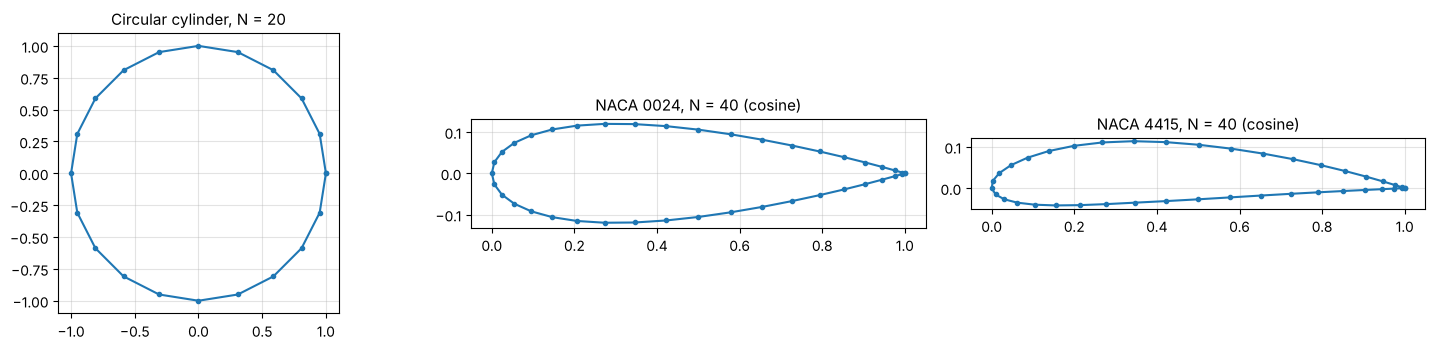

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (name, (xb, yb)) in zip(ax, {
        "Circular cylinder, N = 20": cylinder_panels(20),
        "NACA 0024, N = 40 (cosine)": naca4_panels("0024", 40),
        "NACA 4415, N = 40 (cosine)": naca4_panels("4415", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3)
    a.set_aspect("equal"); a.set_title(name)
plt.tight_layout(); plt.show()

### 2.2 Influence-coefficient helper and the two solvers

In [ ]:
def _local_coords(xb, yb, xc, yc, S, sin_t, cos_t):
    """Control point i expressed in the local frame of panel j (all i, j at once).
    Returns xi, eta, (phi2 - phi1) and ln(r2/r1) as N x N arrays."""
    dx = xc[:, None] - xb[None, :-1]
    dy = yc[:, None] - yb[None, :-1]
    xi  =  dx*cos_t[None, :] + dy*sin_t[None, :]
    eta = -dx*sin_t[None, :] + dy*cos_t[None, :]
    phi1 = np.arctan2(eta, xi)
    phi2 = np.arctan2(eta, xi - S[None, :])
    r1 = np.hypot(xi, eta)
    r2 = np.hypot(xi - S[None, :], eta)
    return xi, eta, phi2 - phi1, np.log(r2/r1)

In [ ]:
def vortex_panel_method_0(xb, yb, alpha_deg, V_inf=1.0):
    """Constant-strength vortex panel method (one gamma per panel).

    Parameters
    ----------
    xb, yb    : boundary points, ordered clockwise (N+1 points, closed body, N panels)
    alpha_deg : angle of attack [deg]
    V_inf     : free-stream speed

    Returns dict with gamma (N), Cp (N), Cl, Gamma, xc, yc, S (all at panels/control points)
    """
    alpha = np.radians(alpha_deg)
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

    # step 1: influence matrix  A[i, j] = normal velocity at point i from unit gamma on panel j
    _, _, dphi, L = _local_coords(xb, yb, xc, yc, S, sin_t, cos_t)
    d = theta[None, :] - theta[:, None]                      # theta_j - theta_i
    A = (dphi*np.sin(d) + L*np.cos(d))/(2*np.pi)
    np.fill_diagonal(A, 0.0)                                  # self-induced normal velocity = 0

    # step 2: right-hand side from the free stream (V_inf . n_i = 0 condition)
    b = V_inf*np.sin(theta - alpha)

    # step 3: Kutta condition gamma_1 + gamma_N = 0 replaces the last equation
    A[-1, :] = 0.0
    A[-1, 0] = 1.0
    A[-1, -1] = 1.0
    b[-1] = 0.0

    # step 4: solve, then post-process
    gamma = np.linalg.solve(A, b)
    Cp = 1.0 - (gamma/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(gamma*S)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "Gamma": Gamma, "xc": xc, "yc": yc, "S": S}

In [ ]:
def vortex_panel_method_1(xb, yb, alpha_deg, V_inf=1.0):
    """Linear-strength vortex panel method (gamma varies linearly on each panel and is
    continuous across panel corners: one unknown gamma per boundary point, N+1 in total).

    Parameters as in vortex_panel_method_0.
    Returns dict with gamma (N+1 nodal values), Cp (N), Cl, Gamma, xc, yc, S.
    """
    alpha = np.radians(alpha_deg)
    xc, yc, S, sin_t, cos_t = panel_geometry(xb, yb)
    N = len(S)
    theta = np.arctan2(sin_t, cos_t)

    # step 1: local geometry; a panel acting on its own midpoint uses special values
    xi, eta, dphi, L = _local_coords(xb, yb, xc, yc, S, sin_t, cos_t)
    k = np.arange(N)
    xi[k, k], eta[k, k], dphi[k, k], L[k, k] = S/2, 0.0, np.pi, 0.0

    # step 2: integrals of the constant (J) and linearly varying (K) parts of gamma
    Sj = S[None, :]
    J1, J2 = dphi, -L
    K1 = xi*dphi + eta*L
    K2 = -xi*L - Sj + eta*dphi

    # step 3: velocity (local axes) per unit gamma_j (a) and per unit gamma_{j+1} (b)
    uxi_a,  uxi_b  =  (J1 - K1/Sj)/(2*np.pi),  (K1/Sj)/(2*np.pi)
    ueta_a, ueta_b = -(J2 - K2/Sj)/(2*np.pi), -(K2/Sj)/(2*np.pi)

    # step 4: normal component at control point i; gamma_j -> column j, gamma_{j+1} -> column j+1
    d = theta[None, :] - theta[:, None]
    s, c = np.sin(d), np.cos(d)
    A = np.zeros((N + 1, N + 1))
    A[:N, :N] += uxi_a*s + ueta_a*c
    A[:N, 1:] += uxi_b*s + ueta_b*c
    b = np.zeros(N + 1)
    b[:N] = V_inf*np.sin(theta - alpha)

    # step 5: Kutta condition gamma_1 + gamma_{N+1} = 0 is the extra (N+1)-th equation
    A[N, 0] = 1.0
    A[N, N] = 1.0

    # step 6: solve, then post-process (surface speed at midpoint = mean of the two nodal values)
    gamma = np.linalg.solve(A, b)
    Vt = 0.5*(gamma[:-1] + gamma[1:])
    Cp = 1.0 - (Vt/V_inf)**2
    chord = xb.max() - xb.min()
    Gamma = np.sum(S*Vt)
    Cl = 2*Gamma/(V_inf*chord)
    return {"gamma": gamma, "Cp": Cp, "Cl": Cl, "Gamma": Gamma, "xc": xc, "yc": yc, "S": S}

## 3. Verification on a circular cylinder

For irrotational flow past a circular cylinder without circulation, $C_p=1-4\sin^2\varphi$ and $C_l=0$ for any $\alpha$. The cylinder is discretised with $N=11,21,\dots,321$ panels (odd $N$, see the remark at the end of Section 4) and the RMS error of $C_p$ at the control points is measured.

    N |     m0 RMS     m0 max      m0 Cl |     m1 RMS     m1 max      m1 Cl
   11 |   6.79e-01   1.09e+00   -1.0e-14 |   1.87e-01   2.99e-01    1.7e-15
   21 |   3.39e-01   5.50e-01    1.2e-14 |   5.31e-02   8.63e-02    8.0e-16
   41 |   1.69e-01   2.76e-01   -1.0e-14 |   1.42e-02   2.31e-02   -4.7e-15
   81 |   8.48e-02   1.38e-01    9.7e-15 |   3.66e-03   5.97e-03   -8.0e-15
  161 |   4.24e-02   6.93e-02    5.6e-14 |   9.29e-04   1.52e-03    3.6e-15
  321 |   2.12e-02   3.46e-02    2.0e-13 |   2.34e-04   3.82e-04   -3.6e-15

Observed order of convergence (RMS error, N roughly doubles):
  N   11 ->   21:  method 0 = 1.00,  method 1 = 1.82
  N   21 ->   41:  method 0 = 1.00,  method 1 = 1.91
  N   41 ->   81:  method 0 = 1.00,  method 1 = 1.95
  N   81 ->  161:  method 0 = 1.00,  method 1 = 1.98
  N  161 ->  321:  method 0 = 1.00,  method 1 = 1.99


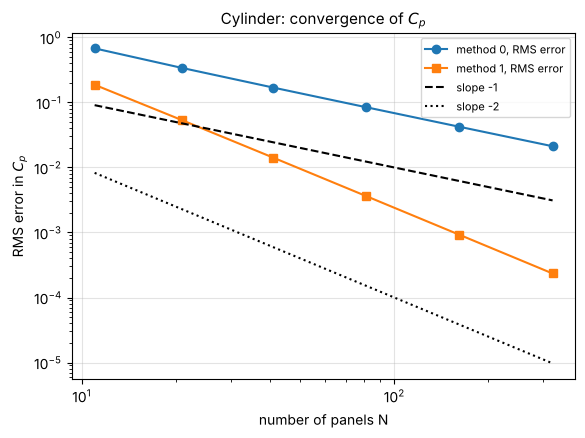

In [ ]:
# Circular cylinder: exact potential flow gives Cp = 1 - 4 sin^2(phi) and Cl = 0 (any alpha)
Ns = [11, 21, 41, 81, 161, 321]
methods = {"method 0 (constant)": vortex_panel_method_0, "method 1 (linear)": vortex_panel_method_1}

def cylinder_errors(method, n):
    xb, yb = cylinder_panels(n)
    r = method(xb, yb, 0.0)
    phi = np.arctan2(r["yc"], r["xc"])
    err = r["Cp"] - (1 - 4*np.sin(phi)**2)
    return np.sqrt(np.mean(err**2)), np.max(np.abs(err)), r["Cl"]

cyl = {name: np.array([cylinder_errors(f, n) for n in Ns]) for name, f in methods.items()}

print(f"{'N':>5} | {'m0 RMS':>10} {'m0 max':>10} {'m0 Cl':>10} | {'m1 RMS':>10} {'m1 max':>10} {'m1 Cl':>10}")
for k, n in enumerate(Ns):
    a, b = cyl["method 0 (constant)"][k], cyl["method 1 (linear)"][k]
    print(f"{n:5d} | {a[0]:10.2e} {a[1]:10.2e} {a[2]:10.1e} | {b[0]:10.2e} {b[1]:10.2e} {b[2]:10.1e}")

print("\nObserved order of convergence (RMS error, N roughly doubles):")
for k in range(1, len(Ns)):
    o0 = np.log2(cyl["method 0 (constant)"][k-1, 0]/cyl["method 0 (constant)"][k, 0])
    o1 = np.log2(cyl["method 1 (linear)"][k-1, 0]/cyl["method 1 (linear)"][k, 0])
    print(f"  N {Ns[k-1]:4d} -> {Ns[k]:4d}:  method 0 = {o0:.2f},  method 1 = {o1:.2f}")

N_arr = np.array(Ns, dtype=float)
plt.figure(figsize=(6.5, 4.5))
plt.loglog(Ns, cyl["method 0 (constant)"][:, 0], "o-", label="method 0, RMS error")
plt.loglog(Ns, cyl["method 1 (linear)"][:, 0], "s-", label="method 1, RMS error")
plt.loglog(Ns, 1.0/N_arr, "k--", label="slope -1")
plt.loglog(Ns, 1.0/N_arr**2, "k:", label="slope -2")
plt.xlabel("number of panels N"); plt.ylabel("RMS error in $C_p$")
plt.title("Cylinder: convergence of $C_p$"); plt.legend(); plt.show()

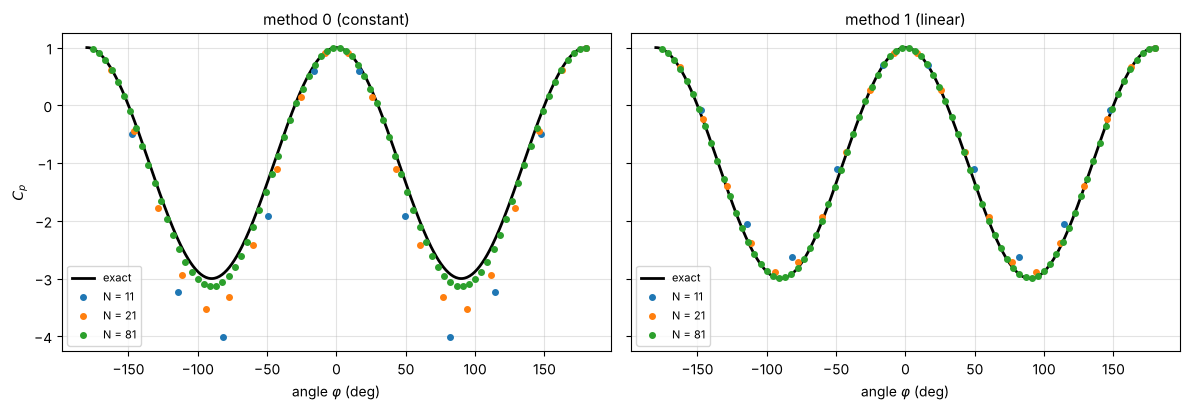

In [ ]:
phi_e = np.linspace(-np.pi, np.pi, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, (name, f) in zip(ax, methods.items()):
    a.plot(np.degrees(phi_e), 1 - 4*np.sin(phi_e)**2, "k", lw=2, label="exact")
    for n in [11, 21, 81]:
        xb, yb = cylinder_panels(n)
        r = f(xb, yb, 0.0)
        a.plot(np.degrees(np.arctan2(r["yc"], r["xc"])), r["Cp"], "o", ms=4, label=f"N = {n}")
    a.set_title(name); a.set_xlabel("angle $\\varphi$ (deg)"); a.legend()
ax[0].set_ylabel("$C_p$")
plt.tight_layout(); plt.show()

### Discussion – cylinder

* **Method 0 (constant strength)** converges with an observed order of **1.00** at every refinement: the RMS $C_p$ error falls from $6.8\times10^{-1}$ ($N=11$) to $2.1\times10^{-2}$ ($N=321$).
* **Method 1 (linear strength)** converges with order **1.8 → 1.99**, i.e. second order: the error falls from $1.9\times10^{-1}$ to $2.3\times10^{-4}$. At $N=321$ it is about 90 times smaller than method 0 for the same panel count, and method 1 with only $N=41$ ($1.4\times10^{-2}$) already beats method 0 with $N=321$.
* The lift coefficient is zero to round-off ($|C_l|<10^{-12}$) for both methods and all $N$, as it must be for a cylinder.
* In the $C_p$ plots the panel points lie on the exact curve; the largest differences are near the top and bottom of the cylinder, where $C_p$ is smallest.

## 4. Verification on a symmetric and a non-symmetric airfoil

There is no closed-form result for NACA 0024 / 4415, so the checks are of three kinds: (i) physical checks with known answers, (ii) convergence of $C_l$ towards a fine-panel reference, and (iii) the effect of the panel-length distribution.

### 4.1 Physical checks

* A symmetric airfoil at $\alpha=0^\circ$ must give $C_l=0$.
* The zero-lift angle of a cambered airfoil is compared with **thin-airfoil theory** for the NACA 4415 camber line, $\alpha_{L0}=-\frac1\pi\int_0^\pi \frac{dy_c}{dx}(\cos\theta-1)\,d\theta$. Thickness shifts the panel-method value slightly away from this camber-only result.
* The lift-curve slope is compared with $2\pi$ and with the potential-flow thickness rule $C_{l\alpha}\approx2\pi(1+0.77\,t/c)$.

In [ ]:
def thin_airfoil_alpha_L0(code):
    """Zero-lift angle (deg) of a NACA 4-digit camber line from thin-airfoil theory."""
    m, p = int(code[0])/100, int(code[1])/10
    if m == 0:
        return 0.0
    th = np.linspace(0, np.pi, 200001)
    x = 0.5*(1 - np.cos(th))
    dyc = np.where(x < p, 2*m/p**2*(p - x), 2*m/(1-p)**2*(p - x))
    return np.degrees(-np.trapezoid(dyc*(np.cos(th) - 1), th)/np.pi)

def lift_curve(code, alphas, method, N=160, spacing="cosine"):
    xb, yb = naca4_panels(code, N, spacing)
    return np.array([method(xb, yb, a)["Cl"] for a in alphas])

def lift_slope_and_alpha0(code, method, N=400):
    """Cl_alpha (per deg) and zero-lift angle (deg) from two angles of attack."""
    a = np.array([0.0, 4.0])
    cl = lift_curve(code, a, method, N)
    slope = (cl[1] - cl[0])/(a[1] - a[0])
    return slope, -cl[0]/slope

print("Check 1 - symmetric airfoil at alpha = 0 must give Cl = 0")
for name, f in methods.items():
    xb, yb = naca4_panels("0024", 160)
    print(f"  NACA 0024, {name}: Cl = {f(xb, yb, 0.0)['Cl']:.2e}")

print("\nCheck 2 - zero-lift angle and lift-curve slope")
print(f"  NACA 4415, thin-airfoil theory (camber line only): alpha_L0 = {thin_airfoil_alpha_L0('4415'):.3f} deg")
for code in ["4415", "0024"]:
    for name, f in methods.items():
        s, a0 = lift_slope_and_alpha0(code, f)
        print(f"  NACA {code}, {name}: alpha_L0 = {a0:7.3f} deg, Cl_alpha = {s:.4f} /deg = {s*180/np.pi/(2*np.pi):.3f} x 2pi")

Check 1 - symmetric airfoil at alpha = 0 must give Cl = 0
  NACA 0024, method 0 (constant): Cl = 8.44e-14
  NACA 0024, method 1 (linear): Cl = 3.55e-15

Check 2 - zero-lift angle and lift-curve slope
  NACA 4415, thin-airfoil theory (camber line only): alpha_L0 = -4.154 deg
  NACA 4415, method 0 (constant): alpha_L0 =  -4.346 deg, Cl_alpha = 0.1231 /deg = 1.123 x 2pi
  NACA 4415, method 1 (linear): alpha_L0 =  -4.345 deg, Cl_alpha = 0.1231 /deg = 1.122 x 2pi
  NACA 0024, method 0 (constant): alpha_L0 =   0.000 deg, Cl_alpha = 0.1322 /deg = 1.205 x 2pi
  NACA 0024, method 1 (linear): alpha_L0 =  -0.000 deg, Cl_alpha = 0.1319 /deg = 1.203 x 2pi


**Results.** Both methods give $C_l\approx10^{-13}$ or smaller for the NACA 0024 at $\alpha=0^\circ$ (symmetry is respected). For the NACA 4415 the panel methods give $\alpha_{L0}=-4.35^\circ$ against $-4.15^\circ$ from thin-airfoil theory: the difference of $0.19^\circ$ is the effect of thickness, which thin-airfoil theory ignores. The lift-curve slopes are $1.12\times2\pi$ (NACA 4415, $t/c=0.15$) and $1.20\times2\pi$ (NACA 0024, $t/c=0.24$). Both are above $2\pi$ and close to $1+0.77\,t/c$ (1.115 and 1.185), which confirms that thickness raises the *inviscid* lift slope. Methods 0 and 1 agree with each other to better than 0.2 % in $C_{l\alpha}$.

### 4.2 Convergence with number of panels and panel distribution

A reference $C_l$ at $\alpha=5^\circ$ is taken from method 1 with $N=1000$ cosine-spaced panels. Both methods are then run with $N=20,\dots,640$ for four distributions of the boundary points:

| spacing | where panels are short |
|---|---|
| `cosine` | leading edge **and** trailing edge |
| `uniform` | nowhere (equal steps in $x$) |
| `le` | leading edge only |
| `te` | trailing edge only |

The error is $|C_l-C_{l,\rm ref}|/C_{l,\rm ref}\times100$ %. The reference is the finest *numerical* solution, not an exact one, so these errors measure convergence, not absolute accuracy (a $10^{-5}$ % floor is applied only so zeros can appear on a log plot).

In [ ]:
alpha = 5.0
airfoils = {"0024": "symmetric", "4415": "non-symmetric"}
N_list = [20, 40, 80, 160, 320, 640]

# Reference: linear-strength method, N = 1000 cosine panels (finest numerical solution)
ref = {}
for code in airfoils:
    xb, yb = naca4_panels(code, 1000, "cosine")
    ref[code] = vortex_panel_method_1(xb, yb, alpha)["Cl"]
    cl0_1000 = vortex_panel_method_0(xb, yb, alpha)["Cl"]
    print(f"NACA {code}: reference Cl (method 1, N=1000) = {ref[code]:.5f};  method 0 at N=1000 gives {cl0_1000:.5f}")

def cl_error_pct(code, method, n, spacing):
    xb, yb = naca4_panels(code, n, spacing)
    return 100*abs(method(xb, yb, alpha)["Cl"] - ref[code])/ref[code]

spacings = ["cosine", "uniform", "le", "te"]
err = {(c, sp, k): [max(cl_error_pct(c, f, n, sp), 1e-5) for n in N_list]
       for c in airfoils for sp in spacings for k, f in enumerate([vortex_panel_method_0, vortex_panel_method_1])}

print("\nPercentage error in Cl at alpha = 5 deg")
print(f"{'airfoil':>7} {'spacing':>8} {'method':>6} | " + " ".join(f"{n:>8d}" for n in N_list))
for c in airfoils:
    for sp in spacings:
        for k in (0, 1):
            print(f"{c:>7} {sp:>8} {k:>6} | " + " ".join(f"{e:8.3f}" for e in err[(c, sp, k)]))

NACA 0024: reference Cl (method 1, N=1000) = 0.65944;  method 0 at N=1000 gives 0.65988
NACA 4415: reference Cl (method 1, N=1000) = 1.14963;  method 0 at N=1000 gives 1.15194

Percentage error in Cl at alpha = 5 deg
airfoil  spacing method |       20       40       80      160      320      640
   0024   cosine      0 |    5.355    0.378    0.541    0.358    0.199    0.104
   0024   cosine      1 |    0.802    0.203    0.050    0.012    0.003    0.000
   0024  uniform      0 |   61.597   34.791   17.410    8.120    3.643    1.587
   0024  uniform      1 |    2.296    0.995    0.414    0.169    0.069    0.029
   0024       le      0 |    5.087    2.007    0.711    0.244    0.075    0.017
   0024       le      1 |    1.707    0.752    0.337    0.153    0.070    0.032
   0024       te      0 |  328.342  198.860  103.959   51.930   25.721   12.708
   0024       te      1 |    2.535    1.073    0.423    0.156    0.055    0.019
   4415   cosine      0 |   17.381    2.617    0.077    0.454  

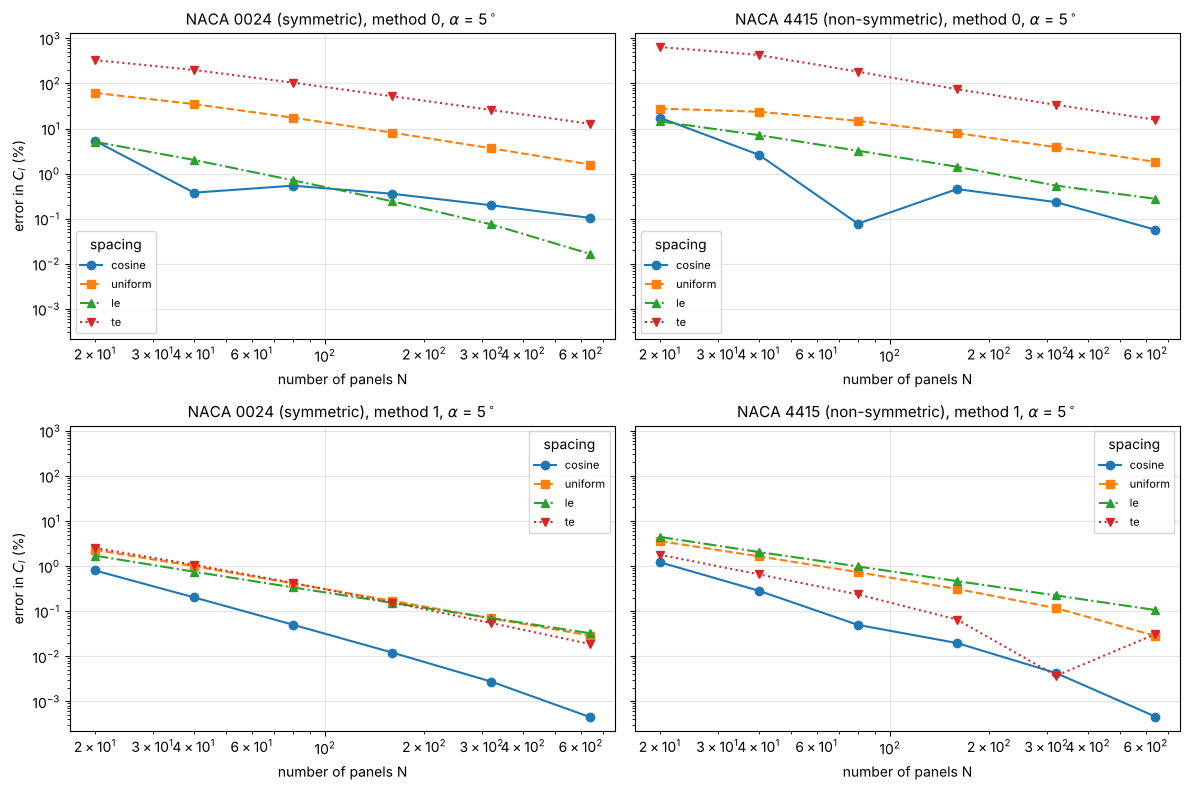

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
styles = {"cosine": "o-", "uniform": "s--", "le": "^-.", "te": "v:"}
for row, k in enumerate((0, 1)):
    for col, c in enumerate(airfoils):
        for sp in spacings:
            ax[row, col].loglog(N_list, err[(c, sp, k)], styles[sp], label=sp)
        ax[row, col].set_title(f"NACA {c} ({airfoils[c]}), method {k}, $\\alpha$ = {alpha:g}$^\\circ$")
        ax[row, col].set_xlabel("number of panels N")
        ax[row, col].legend(title="spacing")
    ax[row, 0].set_ylabel("error in $C_l$ (%)")
plt.tight_layout(); plt.show()

N = 40, cosine  : min Cp =      -1.68
N = 40, uniform : min Cp =      -1.67
N = 40, le      : min Cp =      -1.66
N = 40, te      : min Cp =   -2520.86


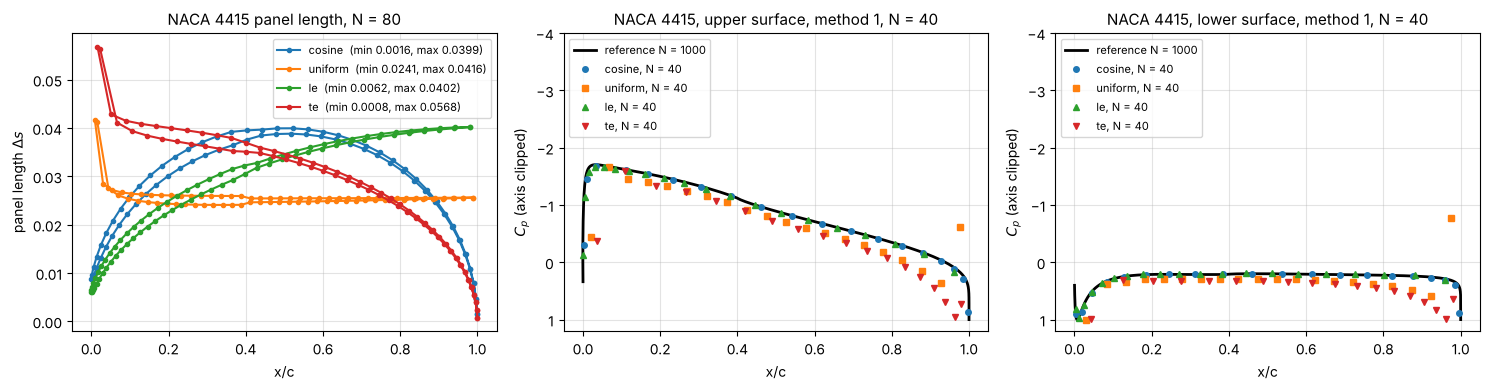

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
Nshow = 80
for sp in spacings:
    xb, yb = naca4_panels("4415", Nshow, sp)
    xc, yc, S, _, _ = panel_geometry(xb, yb)
    ax[0].plot(xc, S, "o-", ms=3, label=f"{sp}  (min {S.min():.4f}, max {S.max():.4f})")
ax[0].set_xlabel("x/c"); ax[0].set_ylabel("panel length $\\Delta s$")
ax[0].set_title(f"NACA 4415 panel length, N = {Nshow}"); ax[0].legend()

# effect of the distribution on the Cp curve for a coarse model, N = 40, method 1
xb, yb = naca4_panels("4415", 1000, "cosine")
r_ref = vortex_panel_method_1(xb, yb, alpha)
lo, up = surface_split(1000)
for a_, name in ((ax[1], "upper surface"), (ax[2], "lower surface")):
    idx = up if name == "upper surface" else lo
    a_.plot(r_ref["xc"][idx], r_ref["Cp"][idx], "k", lw=2, label="reference N = 1000")
for sp, mk in (("cosine", "o"), ("uniform", "s"), ("le", "^"), ("te", "v")):
    xb, yb = naca4_panels("4415", 40, sp)
    r = vortex_panel_method_1(xb, yb, alpha)
    lo4, up4 = surface_split(40)
    ax[1].plot(r["xc"][up4], r["Cp"][up4], mk, ms=4, label=f"{sp}, N = 40")
    ax[2].plot(r["xc"][lo4], r["Cp"][lo4], mk, ms=4, label=f"{sp}, N = 40")
for a_, name in ((ax[1], "upper"), (ax[2], "lower")):
    a_.set_ylim(1.2, -4.0); a_.set_xlabel("x/c"); a_.set_ylabel("$C_p$ (axis clipped)")
    a_.set_title(f"NACA 4415, {name} surface, method 1, N = 40"); a_.legend()
plt.tight_layout(); plt.show()
for sp in spacings:
    xb, yb = naca4_panels("4415", 40, sp)
    print(f"N = 40, {sp:8s}: min Cp = {vortex_panel_method_1(xb, yb, alpha)['Cp'].min():10.2f}")

### Discussion – convergence and panel distribution

* **Method 1 + cosine spacing is by far the best combination.** The $C_l$ error is 0.8 % (NACA 0024) and 1.2 % (NACA 4415) at $N=20$, and drops by a factor of about 4 per doubling (second order) to 0.012 % / 0.020 % at $N=160$. $N=40$–$80$ is enough for errors of 0.05–0.3 %.
* **Method 0 is less accurate and not monotonic.** With cosine spacing its error settles in the range 0.1–0.5 % (0.358 % at $N=160$ and 0.104 % at $N=640$ for NACA 0024) and does not decrease smoothly; for NACA 4415 it jumps from 2.6 % ($N=40$) to 0.08 % ($N=80$) and back to 0.45 % ($N=160$). The dip at $N=80$ is a chance crossing of the reference value. Also, method 0 at $N=1000$ gives $C_l$ = 0.6599 and 1.1519, i.e. +0.07 % and +0.20 % relative to the method 1 reference, so the two methods approach the same limit only slowly.
* **Uniform spacing needs many more panels.** For method 1, uniform spacing gives 2.3 % (0024) / 3.6 % (4415) at $N=20$ and still 0.03 % at $N=640$ (error falls only about 2.2–2.7 times per doubling, not 4); for method 0 the error is 62 % / 28 % at $N=20$ and still 1.6–1.8 % at $N=640$. Panels are too long at the leading edge, where $C_p$ changes fastest.
* **Where the panels are clustered matters.** Clustering at the leading edge only (`le`) is much better than uniform for method 0 (0.017 % vs 1.6 % at $N=640$ for NACA 0024) but worse than `cosine` for method 1 at small $N$. Clustering at the trailing edge only (`te`) is the worst choice for method 0 (329 % at $N=20$, still 12.7 % at $N=640$ for NACA 0024) because the leading-edge panels are then very long (for the NACA 4415 at $N=80$ the longest panel is 0.057 against 0.040 for cosine). Method 1 is much more tolerant ($C_l$ error 2.5 % → 0.02 %), but the local $C_p$ is still wrong: at $N=40$ the `te` distribution produces an unphysical $C_p\approx-2500$ at the trailing-edge end (see the clipped plot below), although its $C_l$ error is only 0.7 %. **A small error in $C_l$ does not guarantee a correct $C_p$ distribution.**
* **Conclusion:** use linear strength with cosine-type spacing. The panel-length plot shows why: the cosine panels are 0.0016 long at the ends against 0.040 at mid-chord, while uniform panels are roughly 0.025 everywhere.

### Remark – method 0 and the odd–even (saw-tooth) mode

For method 0 the $C_l$ values above are reliable, but the panel-wise **vortex strength and hence $C_p$ show an alternating (saw-tooth) pattern on airfoils**. The next cell demonstrates this.

airfoil    N | max|g| m0 max|g| m1 |    Cl m0    Cl m1
   0024   40 |      3.89      1.65 |   0.6619   0.6581
   0024   80 |      7.74      1.66 |   0.6630   0.6591
   0024  160 |     16.59      1.66 |   0.6618   0.6594
   0024  320 |     34.11      1.66 |   0.6607   0.6594
   4415   40 |      4.65      1.64 |   1.1797   1.1464
   4415   80 |      3.71      1.64 |   1.1487   1.1491
   4415  160 |     13.76      1.64 |   1.1549   1.1494
   4415  320 |     34.35      1.64 |   1.1523   1.1496

Cylinder, method 0: even vs odd N (RMS Cp error)
  N =  20: 4.987e+00
  N =  21: 3.387e-01
  N =  40: 1.134e+00
  N =  41: 1.695e-01
  N =  80: 2.445e+00
  N =  81: 8.479e-02


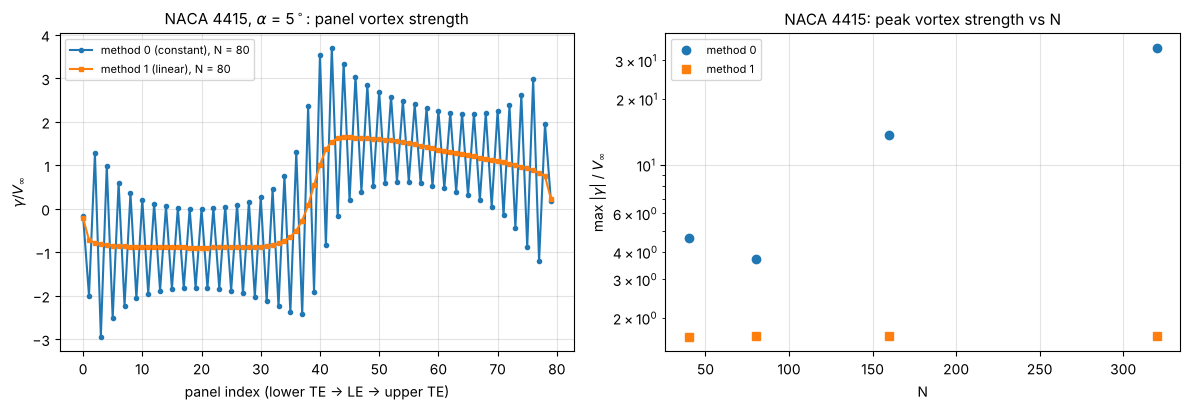

In [ ]:
# Why method 0 is used for C_l but not for airfoil C_p: odd-even (saw-tooth) mode in gamma.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
xb, yb = naca4_panels("4415", 80, "cosine")
r0, r1 = vortex_panel_method_0(xb, yb, alpha), vortex_panel_method_1(xb, yb, alpha)
ax[0].plot(r0["gamma"], "o-", ms=3, label="method 0 (constant), N = 80")
ax[0].plot(0.5*(r1["gamma"][:-1] + r1["gamma"][1:]), "s-", ms=3, label="method 1 (linear), N = 80")
ax[0].set_xlabel("panel index (lower TE -> LE -> upper TE)"); ax[0].set_ylabel("$\\gamma / V_\\infty$")
ax[0].set_title("NACA 4415, $\\alpha$ = 5$^\\circ$: panel vortex strength"); ax[0].legend()

print(f"{'airfoil':>7} {'N':>4} | {'max|g| m0':>9} {'max|g| m1':>9} | {'Cl m0':>8} {'Cl m1':>8}")
for c in airfoils:
    for n in (40, 80, 160, 320):
        xb, yb = naca4_panels(c, n, "cosine")
        a0, a1 = vortex_panel_method_0(xb, yb, alpha), vortex_panel_method_1(xb, yb, alpha)
        print(f"{c:>7} {n:4d} | {np.abs(a0['gamma']).max():9.2f} {np.abs(a1['gamma']).max():9.2f} | {a0['Cl']:8.4f} {a1['Cl']:8.4f}")
        if c == "4415":
            ax[1].semilogy(n, np.abs(a0["gamma"]).max(), "o", color="C0")
            ax[1].semilogy(n, np.abs(a1["gamma"]).max(), "s", color="C1")
ax[1].plot([], [], "o", color="C0", label="method 0"); ax[1].plot([], [], "s", color="C1", label="method 1")
ax[1].set_xlabel("N"); ax[1].set_ylabel("max |$\\gamma$| / $V_\\infty$"); ax[1].set_title("NACA 4415: peak vortex strength vs N"); ax[1].legend()
plt.tight_layout(); plt.show()

print("\nCylinder, method 0: even vs odd N (RMS Cp error)")
for n in (20, 21, 40, 41, 80, 81):
    print(f"  N = {n:3d}: {cylinder_errors(vortex_panel_method_0, n)[0]:.3e}")

**Why this happens.** The normal-velocity condition for a vortex sheet is a singular (first-kind) integral equation. Its discrete matrix has an almost-null mode that alternates in sign from panel to panel, which the single Kutta row cannot suppress for an even number of panels, because $\gamma_1+\gamma_N=0$ is satisfied by an alternating pattern when $N$ is even. The alternating parts largely cancel in $\Gamma=\sum\gamma S$, so $C_l$ stays accurate, but the individual $\gamma_i$ (and so $C_p=1-\gamma_i^2$) do not: the peak $|\gamma|$ of method 0 grows with $N$ (3.7 → 34 on the NACA 4415 from $N=80$ to $320$), while for method 1 it stays at 1.64. Linear panels with continuous $\gamma$ do not have this problem.

On the cylinder, even $N$ gives errors of order 1–5 in $C_p$ (e.g. 4.99 at $N=20$) against 0.34 for $N=21$; this is why odd $N$ was used in Section 3. For the airfoil, $N$ has to be even in `naca4_panels` ($N/2$ panels per surface).

**Consequence for the rest of the report:** $C_l$ is compared for both methods; $C_p$ distributions on airfoils are plotted from **method 1**.

## 5. Prediction of airfoil characteristics

NACA 0024 (symmetric) and NACA 4415 (non-symmetric), $N=160$ cosine-spaced panels.

### 5.1 Lift curves

 alpha | 0024 m0     m1    | 4415 m0     m1   
  -4.0 |  -0.5297  -0.5277 |   0.0510   0.0398
  -2.0 |  -0.2650  -0.2640 |   0.2974   0.2874
   0.0 |   0.0000   0.0000 |   0.5434   0.5347
   2.0 |   0.2650   0.2640 |   0.7887   0.7813
   4.0 |   0.5297   0.5277 |   1.0331   1.0270
   6.0 |   0.7937   0.7908 |   1.2762   1.2714
   8.0 |   1.0568   1.0529 |   1.5178   1.5143
  10.0 |   1.3186   1.3137 |   1.7575   1.7554


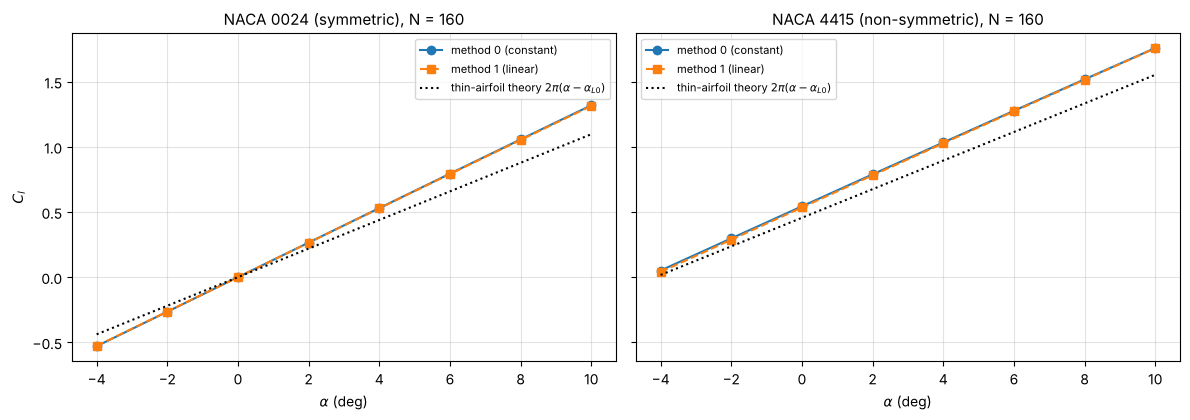

In [ ]:
N_pred = 160
alphas = np.arange(-4, 11, 2.0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
table = {}
for a_, code in zip(ax, airfoils):
    for name, f in methods.items():
        cl = lift_curve(code, alphas, f, N_pred)
        table[(code, name)] = cl
        a_.plot(alphas, cl, "o-" if name.startswith("method 0") else "s--", label=name)
    s2pi = 2*np.pi*np.radians(alphas - thin_airfoil_alpha_L0(code))
    a_.plot(alphas, s2pi, "k:", label="thin-airfoil theory $2\\pi(\\alpha-\\alpha_{L0})$")
    a_.set_title(f"NACA {code} ({airfoils[code]}), N = {N_pred}")
    a_.set_xlabel("$\\alpha$ (deg)"); a_.legend()
ax[0].set_ylabel("$C_l$")
plt.tight_layout(); plt.show()

print(f"{'alpha':>6} | " + " | ".join(f"{c} m0     m1   " for c in airfoils))
for i, a in enumerate(alphas):
    print(f"{a:6.1f} | " + " | ".join(f"{table[(c, 'method 0 (constant)')][i]:8.4f} {table[(c, 'method 1 (linear)')][i]:8.4f}" for c in airfoils))

### 5.2 Pressure-coefficient distributions

$C_p$ on the upper and lower surfaces at $\alpha=0^\circ$ and $6^\circ$ (method 1, inverted axis so suction is up).

NACA 0024, alpha =   0:  Cl = 0.0000;  max Cp = 0.993;  min Cp = -0.847 at x/c = 0.168 (lower surface)
NACA 0024, alpha =   6:  Cl = 0.7908;  max Cp = 0.998;  min Cp = -1.994 at x/c = 0.059 (upper surface)
NACA 4415, alpha =   0:  Cl = 0.5347;  max Cp = 0.996;  min Cp = -0.901 at x/c = 0.242 (upper surface)
NACA 4415, alpha =   6:  Cl = 1.2714;  max Cp = 0.997;  min Cp = -2.060 at x/c = 0.016 (upper surface)


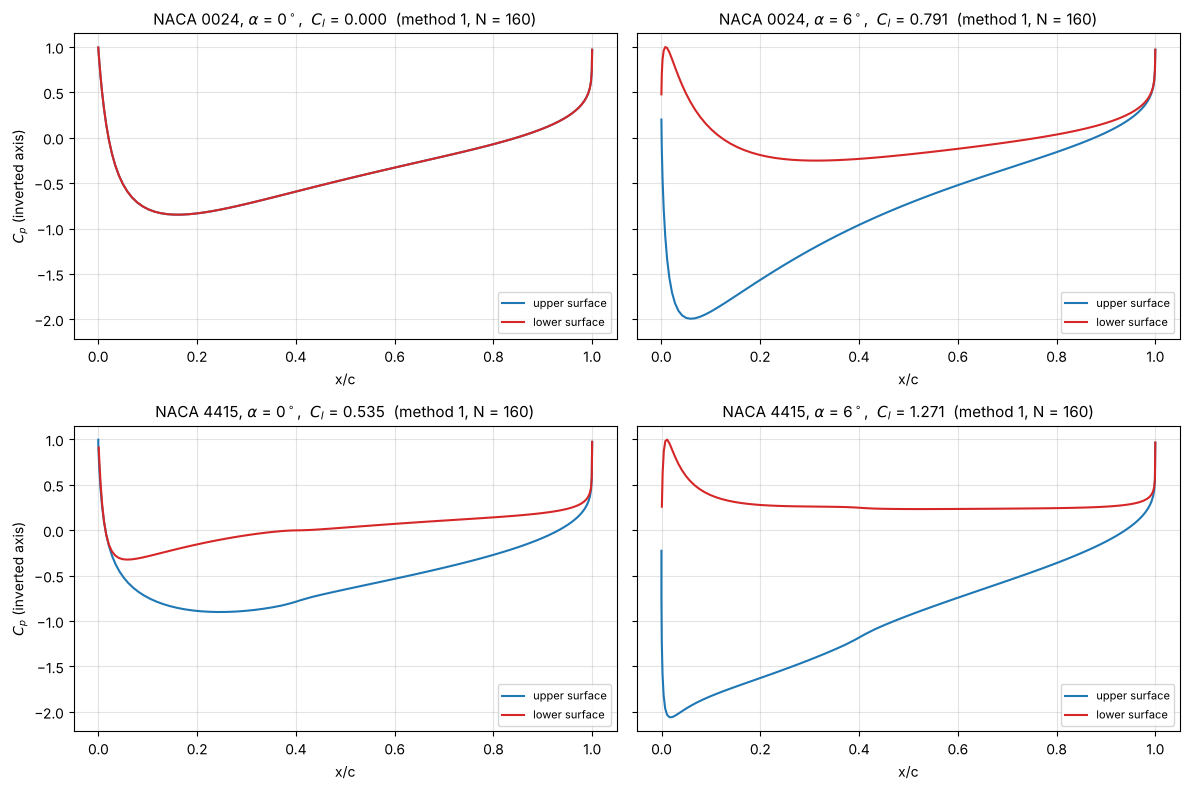

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for row, code in enumerate(airfoils):
    xb, yb = naca4_panels(code, N_pred, "cosine")
    lo, up = surface_split(N_pred)
    for col, a in enumerate([0.0, 6.0]):
        r1 = vortex_panel_method_1(xb, yb, a)
        A_ = ax[row, col]
        A_.plot(r1["xc"][up], r1["Cp"][up], "-", color="C0", label="upper surface")
        A_.plot(r1["xc"][lo], r1["Cp"][lo], "-", color="C3", label="lower surface")
        A_.invert_yaxis()
        A_.set_title(f"NACA {code}, $\\alpha$ = {a:g}$^\\circ$,  $C_l$ = {r1['Cl']:.3f}  (method 1, N = {N_pred})")
        A_.set_xlabel("x/c"); A_.legend(loc="lower right")
        print(f"NACA {code}, alpha = {a:3.0f}:  Cl = {r1['Cl']:.4f};  max Cp = {r1['Cp'].max():.3f};  "
              f"min Cp = {r1['Cp'].min():.3f} at x/c = {r1['xc'][np.argmin(r1['Cp'])]:.3f} "
              f"({'upper' if np.argmin(r1['Cp']) >= N_pred//2 else 'lower'} surface)")
    ax[row, 0].set_ylabel("$C_p$ (inverted axis)")
plt.tight_layout(); plt.show()

### Discussion – predicted characteristics

* **Lift.** Both airfoils have a linear $C_l$–$\alpha$ curve in the potential-flow model. NACA 0024: $C_l=0$ at $0^\circ$, 0.791 at $6^\circ$ (method 1), slope $\approx0.132$ per degree (about $1.20\times2\pi$). NACA 4415: $C_l=0.535$ at $0^\circ$ and 1.271 at $6^\circ$, zero lift at $\alpha_{L0}\approx-4.35^\circ$, slope $\approx0.123$ per degree ($1.12\times2\pi$). Camber moves the whole curve up by $\Delta C_l\approx0.535$ at $0^\circ$; the thicker section has the larger slope. The two methods differ by less than 0.012 in $C_l$ over the whole range.
* **NACA 0024, $\alpha=0^\circ$.** The upper and lower $C_p$ curves coincide (symmetry). $C_p\approx1$ at the stagnation point, minimum $C_p=-0.85$ at $x/c\approx0.17$ (maximum thickness is at $x/c=0.30$), then a smooth recovery to $C_p\approx1$ at the trailing edge.
* **NACA 0024, $\alpha=6^\circ$.** The upper surface has a suction peak $C_p=-1.99$ at $x/c=0.06$ and the lower surface $C_p$ between about $-0.25$ and $+0.09$ over $0.15<x/c<0.85$; the area between the curves gives $C_l=0.791$.
* **NACA 4415, $\alpha=0^\circ$.** Already non-symmetric: upper-surface suction (minimum $-0.90$ at $x/c=0.24$) and a lower surface close to the free-stream pressure ($C_p$ between about $-0.2$ and $+0.16$ for $0.15<x/c<0.85$), producing $C_l=0.535$.
* **NACA 4415, $\alpha=6^\circ$.** The suction peak rises to $C_p=-2.06$ and moves forward to $x/c=0.016$ near the leading edge, followed by a long adverse-pressure-gradient recovery over the rear upper surface; $C_l=1.271$.
* All curves reach $C_p\to1$ at the trailing edge, as the Kutta condition with a closed trailing edge requires. This is an inviscid feature; real flows have a lower pressure there.

## 6. Limitations: accuracy of the prediction vs airfoil thickness

A panel method solves **inviscid, irrotational, attached** flow. It has no way to represent boundary-layer growth or separation, and so it cannot tell by itself where the real flow departs from it. What the functions *can* do is show how the inviscid solution changes with thickness, and what that implies for the viscous flow.

Symmetric NACA 00xx sections with $t/c=6\ldots30\%$ (NACA 0024 included) are analysed with method 1 at $\alpha=5^\circ$, $N=200$, cosine spacing. Besides $C_l$ and $C_p$, three indicators are computed:

* the lift-curve slope $C_{l\alpha}/2\pi$, compared with $1+0.77\,t/c$;
* the mean **adverse pressure gradient** on the upper surface between $x/c=0.5$ and $0.95$, $\big[C_p(0.95)-C_p(0.5)\big]/0.45$, which the boundary layer must overcome;
* the **trailing-edge wedge angle** between the upper and lower surfaces (the panel method forces the flow to leave smoothly through this wedge with $C_p\to1$).

 t/c %  Cl(5deg)  Cla/2pi  1+.77t  min Cp aft dCp/dx  TE wedge  Cp(0.95)
     6    0.5752    1.049   1.046  -4.954      0.718      8.3d     0.027
     9    0.5890    1.074   1.069  -2.785      0.925     12.4d     0.058
    12    0.6030    1.100   1.092  -2.055      1.135     16.5d     0.089
    15    0.6170    1.125   1.115  -1.777      1.348     20.6d     0.121
    18    0.6310    1.151   1.139  -1.685      1.561     24.6d     0.152
    21    0.6452    1.177   1.162  -1.689      1.776     28.5d     0.183
    24    0.6594    1.203   1.185  -1.744      1.992     32.4d     0.214
    27    0.6737    1.229   1.208  -1.830      2.207     36.2d     0.245
    30    0.6880    1.255   1.231  -1.934      2.422     39.9d     0.275


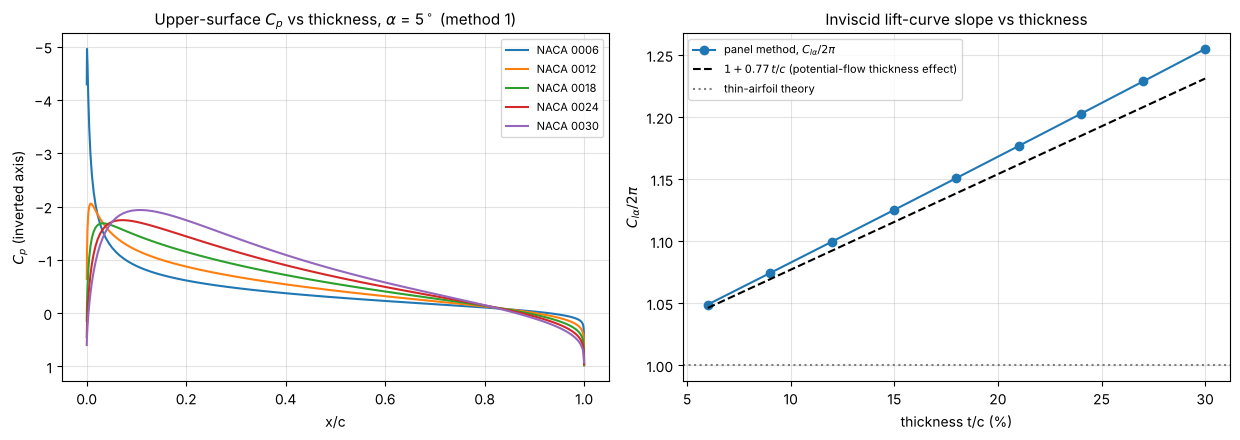

In [ ]:
def te_wedge_angle(xb, yb):
    """Included angle (deg) between the upper and lower surface at the trailing edge."""
    vu = np.array([xb[-2] - xb[-1], yb[-2] - yb[-1]])
    vl = np.array([xb[1] - xb[0],  yb[1] - yb[0]])
    return np.degrees(np.arccos(vu @ vl/np.linalg.norm(vu)/np.linalg.norm(vl)))

t_pct = np.array([6, 9, 12, 15, 18, 21, 24, 27, 30])
N_t, alpha_t = 200, 5.0
lo, up = surface_split(N_t)
rows = []
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
for t in t_pct:
    code = f"00{t:02d}"
    xb, yb = naca4_panels(code, N_t, "cosine")
    r5 = vortex_panel_method_1(xb, yb, alpha_t)
    r0 = vortex_panel_method_1(xb, yb, 0.0)
    slope = (r5["Cl"] - r0["Cl"])/alpha_t                       # per deg
    xu, cu = r5["xc"][up], r5["Cp"][up]
    grad = (np.interp(0.95, xu, cu) - np.interp(0.5, xu, cu))/0.45   # mean adverse gradient 0.5 < x/c < 0.95
    rows.append((t, r5["Cl"], slope*180/np.pi/(2*np.pi), 1 + 0.77*t/100, cu.min(), grad,
                 te_wedge_angle(xb, yb), np.interp(0.95, xu, cu)))
    if t in (6, 12, 18, 24, 30):
        ax[0].plot(xu, cu, label=f"NACA {code}")
ax[0].invert_yaxis(); ax[0].set_xlabel("x/c"); ax[0].set_ylabel("$C_p$ (inverted axis)")
ax[0].set_title(f"Upper-surface $C_p$ vs thickness, $\\alpha$ = {alpha_t:g}$^\\circ$ (method 1)"); ax[0].legend()
rows = np.array(rows)

ax[1].plot(t_pct, rows[:, 2], "o-", label="panel method, $C_{l\\alpha}/2\\pi$")
ax[1].plot(t_pct, rows[:, 3], "k--", label="$1 + 0.77\\,t/c$ (potential-flow thickness effect)")
ax[1].axhline(1.0, color="gray", ls=":", label="thin-airfoil theory")
ax[1].set_xlabel("thickness t/c (%)"); ax[1].set_ylabel("$C_{l\\alpha} / 2\\pi$")
ax[1].set_title("Inviscid lift-curve slope vs thickness"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"{'t/c %':>6} {'Cl(5deg)':>9} {'Cla/2pi':>8} {'1+.77t':>7} {'min Cp':>7} {'aft dCp/dx':>10} {'TE wedge':>9} {'Cp(0.95)':>9}")
for r in rows:
    print(f"{r[0]:6.0f} {r[1]:9.4f} {r[2]:8.3f} {r[3]:7.3f} {r[4]:7.3f} {r[5]:10.3f} {r[6]:8.1f}d {r[7]:9.3f}")

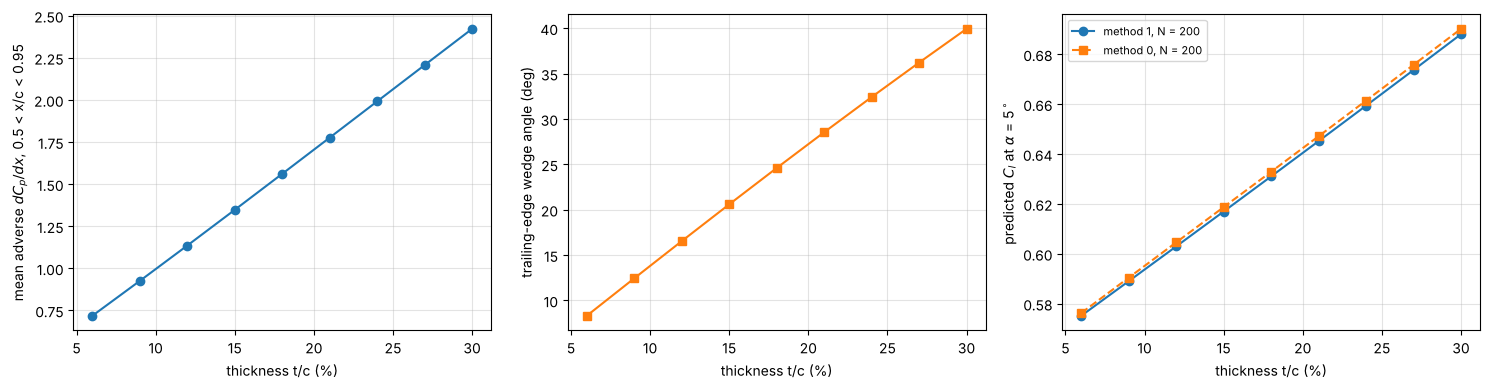

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(t_pct, rows[:, 5], "o-"); ax[0].set_ylabel("mean adverse $dC_p/dx$, 0.5 < x/c < 0.95")
ax[1].plot(t_pct, rows[:, 6], "s-", color="C1"); ax[1].set_ylabel("trailing-edge wedge angle (deg)")
ax[2].plot(t_pct, rows[:, 1], "o-", label="method 1, N = 200")
cl_m0 = [vortex_panel_method_0(*naca4_panels(f"00{t:02d}", N_t), alpha_t)["Cl"] for t in t_pct]
ax[2].plot(t_pct, cl_m0, "s--", label="method 0, N = 200"); ax[2].set_ylabel(f"predicted $C_l$ at $\\alpha$ = {alpha_t:g}$^\\circ$"); ax[2].legend()
for a_ in ax:
    a_.set_xlabel("thickness t/c (%)")
plt.tight_layout(); plt.show()

### Discussion – limitation with thickness

* **The inviscid lift keeps rising with thickness.** Between NACA 0006 and 0030, the predicted $C_l$ at $5^\circ$ rises from 0.575 to 0.688 (+20 %), and $C_{l\alpha}/2\pi$ from 1.049 to 1.255, following $1+0.77\,t/c$ (1.046 → 1.231) to within 2 %. The two methods give the same trend. This is what potential flow predicts; it is a *thickness effect of the inviscid model*, and it does not describe real thick wings.
* **The loading the boundary layer must carry grows rapidly.** The mean adverse pressure gradient on the rear upper surface grows 3.4 times, from 0.72 (6 %) to 2.42 (30 %) (1.99 for the 24 % thick NACA 0024), $C_p$ at $x/c=0.95$ rises from 0.03 to 0.28, and the trailing-edge wedge angle grows from 8° to 40° (32° for NACA 0024). A real boundary layer cannot follow a pressure rise of this size over a surface that closes at such an angle: it thickens, separates ahead of the trailing edge and leaves a wake, so the real pressure at the rear does not recover to $C_p\approx1$ and the real lift is lower than the potential-flow value. The thicker the section, the larger the part of the flow that the model ignores.
* The suction peak itself does not become a better predictor either: $\min C_p$ is $-4.95$ for the 6 % section but only $-1.7$ to $-1.9$ for 18–30 %, so the flow over thick airfoils is dominated by the extended adverse-gradient region, not by a sharp leading-edge peak.
* **What this notebook does not do.** No viscous solver or wind-tunnel data are included, so the *size* of the discrepancy is not computed here. To quantify it, overlay measured $C_l$–$\alpha$ data for the NACA 0024 and a thin section from Abbott & von Doenhoff (ref. 5) on the panel-method curves; the measured lift slope and maximum lift are expected to fall further and further short of the inviscid prediction as thickness increases, while the panel method keeps predicting a higher slope.
* **Practical conclusion:** the predictive capability of vortex panel methods is best for thin sections at small $\alpha$ and deteriorates as thickness increases. For thick airfoils the potential-flow solution needs to be coupled with a boundary-layer calculation (viscous–inviscid interaction, e.g. XFOIL).

## 7. Conclusions

1. **Algorithms and code.** Constant-strength (`vortex_panel_method_0`) and linear-strength (`vortex_panel_method_1`) vortex panel methods were written as step-by-step algorithms and implemented as Python functions that take the boundary points, angle of attack and speed, and return $\gamma$, $C_p$, $C_l$, $\Gamma$ and panel data.
2. **Cylinder.** The RMS $C_p$ error converges at order 1.0 for constant strength and 1.8–2.0 for linear strength; $C_l=0$ to round-off.
3. **NACA 0024 and 4415.** The symmetric section gives $C_l=0$ at $\alpha=0$; for the 4415 $\alpha_{L0}=-4.35^\circ$ against $-4.15^\circ$ from thin-airfoil theory, and the lift slopes follow $2\pi(1+0.77\,t/c)$. Linear strength with cosine spacing reaches 0.05 % error in $C_l$ with 80 panels; uniform spacing needs several times as many panels for the same accuracy, and trailing-edge-only clustering is unreliable.
4. **Method 0 caveat.** Its $C_l$ is accurate to about 0.1–0.5 %, but its panel-wise $\gamma$ and $C_p$ contain a saw-tooth that grows with $N$ on airfoils (and it needs odd $N$ on a cylinder). $C_p$ results are therefore taken from method 1.
5. **Thickness.** The potential-flow lift and the severity of the aft pressure recovery both increase steadily with thickness (to $t/c=30\%$) while real flow separates earlier, so the predictive capability of panel methods decreases for thick airfoils.

## 8. References and acknowledgements

**Books and reports**
1. J. Katz and A. Plotkin, *Low-Speed Aerodynamics*, 2nd ed., Cambridge University Press, 2001 – constant and linear vortex panel formulations.
2. J. D. Anderson, *Fundamentals of Aerodynamics*, McGraw-Hill – vortex panel method, thin-airfoil theory, flow over a cylinder.
3. J. Moran, *An Introduction to Theoretical and Computational Aerodynamics*, Wiley, 1984 – panel methods and the Kutta condition.
4. A. M. Kuethe and C.-Y. Chow, *Foundations of Aerodynamics*, Wiley – NACA 4-digit thickness and camber formulae, thin-airfoil theory.
5. I. H. Abbott and A. E. von Doenhoff, *Theory of Wing Sections*, Dover, 1959 – NACA 4-digit geometry and wind-tunnel data (use for the comparison suggested in Section 6).
6. J. L. Hess and A. M. O. Smith, "Calculation of potential flow about arbitrary bodies," *Progress in Aerospace Sciences* 8, 1967 – the origin of panel methods.


**Discussions with colleagues:** Discussed with several seniors and friends to understand the overview approach for completion the assignment.

**Use of AI:** The ChatGpt and Gemini was used to generate the code.
